In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

In [29]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target

print("Shape X:", X.shape, "| Shape y:", y.shape)
print("Valores nulos em X:", X.isna().sum().sum(), "| Nulos em y:", y.isna().sum())
display(X.describe())

Shape X: (20640, 8) | Shape y: (20640,)
Valores nulos em X: 0 | Nulos em y: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [15]:
print("Resumo de y (em US$):")
display((y * 100_000).describe())


Resumo de y (em US$):


,MedHouseVal
count,20640.000000
mean,206855.816909
std,115395.615874
min,14999.000000
25%,119600.000000
50%,179700.000000
75%,264725.000000
max,500001.000000


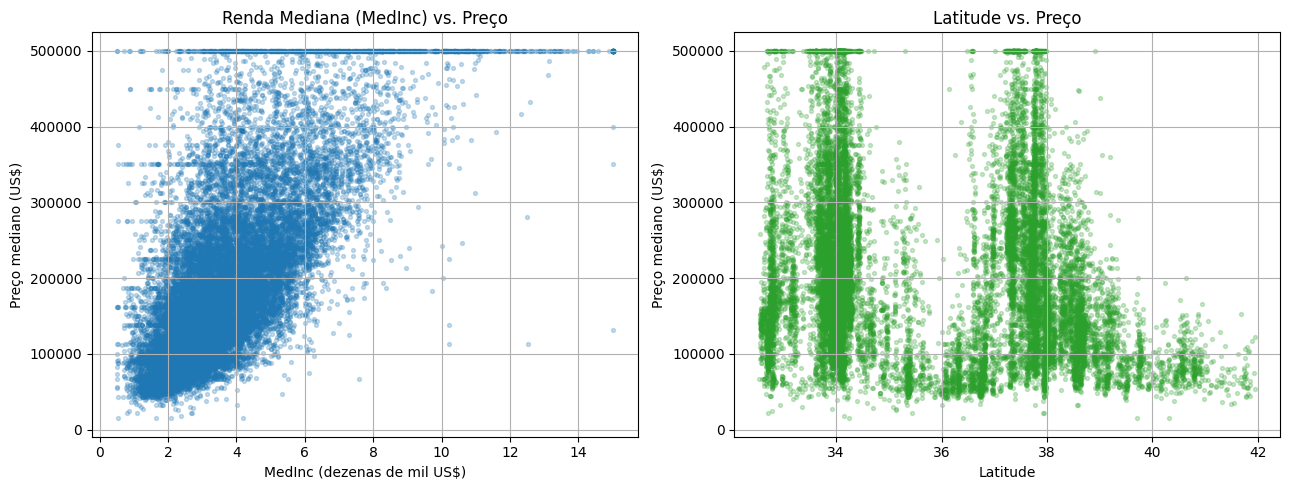

In [28]:
preco_usd = y * 100_000

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X["MedInc"], preco_usd, alpha=0.25, s=8)
axes[0].set_title("Renda Mediana (MedInc) vs. Preço")
axes[0].set_xlabel("MedInc (dezenas de mil US$)")
axes[0].set_ylabel("Preço mediano (US$)")
axes[0].grid(True)

axes[1].scatter(X["Latitude"], preco_usd, alpha=0.25, s=8, color="tab:green")
axes[1].set_title("Latitude vs. Preço")
axes[1].set_xlabel("Latitude")
axes[1].set_ylabel("Preço mediano (US$)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [27]:
X_raw = X.to_numpy()
y_raw = y.to_numpy().reshape(-1, 1)

X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X_raw, y_raw, test_size=0.30, random_state=42
)

X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.50, random_state=42
)

print(f"Treino:    {X_train_raw.shape[0]} amostras ({X_train_raw.shape[0]/len(X_raw):.1%})")
print(f"Validação: {X_val_raw.shape[0]} amostras ({X_val_raw.shape[0]/len(X_raw):.1%})")
print(f"Teste:     {X_test_raw.shape[0]} amostras ({X_test_raw.shape[0]/len(X_raw):.1%})")

x_scaler = StandardScaler().fit(X_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

x_train = torch.from_numpy(x_scaler.transform(X_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()

x_val = torch.from_numpy(x_scaler.transform(X_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()

x_test = torch.from_numpy(x_scaler.transform(X_test_raw)).float()
y_test = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

Treino:    14448 amostras (70.0%)
Validação: 3096 amostras (15.0%)
Teste:     3096 amostras (15.0%)


In [20]:
model = nn.Linear(8, 1)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.1)


def train_epoch(model, optimizer, criterion, x_t, y_t):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_t)
    loss = criterion(y_pred, y_t)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x_v, y_v):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_v)
        loss = criterion(y_pred, y_v)
    return loss.item()


n_epochs = 300
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    t_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    v_loss = validate_epoch(model, criterion, x_val, y_val)
    train_losses.append(t_loss)
    val_losses.append(v_loss)

    if (epoch + 1) % 50 == 0:
        print(f"Época [{epoch+1}/{n_epochs}] - Train Loss: {t_loss:.5f} | Val Loss: {v_loss:.5f}")


Época [50/300] - Train Loss: 0.41196 | Val Loss: 0.42401
Época [100/300] - Train Loss: 0.39548 | Val Loss: 0.40850
Época [150/300] - Train Loss: 0.39186 | Val Loss: 0.40506
Época [200/300] - Train Loss: 0.39099 | Val Loss: 0.40420
Época [250/300] - Train Loss: 0.39076 | Val Loss: 0.40394
Época [300/300] - Train Loss: 0.39069 | Val Loss: 0.40384


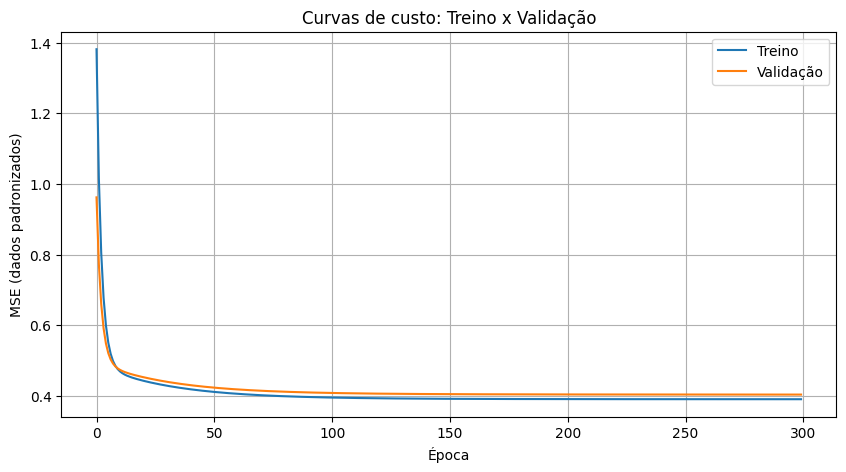

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(range(n_epochs), train_losses, label="Treino")
plt.plot(range(n_epochs), val_losses, label="Validação")
plt.xlabel("Época")
plt.ylabel("MSE (dados padronizados)")
plt.title("Curvas de custo: Treino x Validação")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
model.eval()
with torch.no_grad():
    y_test_pred_scaled = model(x_test).numpy()

y_test_pred_usd = y_scaler.inverse_transform(y_test_pred_scaled) * 100_000
y_test_true_usd = y_test_raw * 100_000

baseline_usd = np.full_like(y_test_true_usd, fill_value=y_train_raw.mean() * 100_000)

rmse_modelo_usd = np.sqrt(np.mean((y_test_pred_usd - y_test_true_usd) ** 2))
rmse_baseline_usd = np.sqrt(np.mean((baseline_usd - y_test_true_usd) ** 2))

print(f"RMSE Modelo (Teste):   US$ {rmse_modelo_usd:,.2f}")
print(f"RMSE Baseline (Teste): US$ {rmse_baseline_usd:,.2f}")
print(f"Redução de erro vs. baseline: {(1 - rmse_modelo_usd / rmse_baseline_usd):.1%}")

RMSE Modelo (Teste):   US$ 72,157.28
RMSE Baseline (Teste): US$ 114,992.22
Redução de erro vs. baseline: 37.3%


Bias (w0, escala padronizada): 0.000000


,variavel,peso_padronizado,peso_absoluto
0,MedInc,0.738520,0.738520
3,AveBedrms,0.306417,0.306417
1,HouseAge,0.107291,0.107291
4,Population,-0.000167,0.000167
5,AveOccup,-0.036332,0.036332
2,AveRooms,-0.266263,0.266263
7,Longitude,-0.733681,0.733681
6,Latitude,-0.754987,0.754987


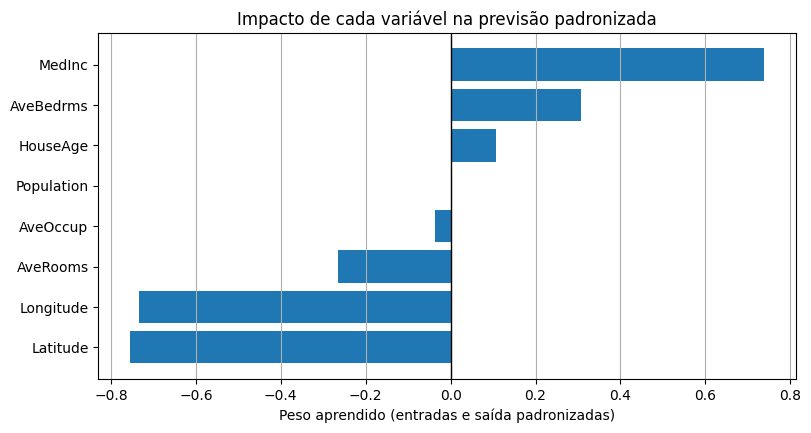

In [22]:
pesos = model.weight.detach().numpy().flatten()
bias = model.bias.item()

df_pesos = pd.DataFrame({
    "variavel": X.columns,
    "peso_padronizado": pesos,
    "peso_absoluto": np.abs(pesos),
}).sort_values("peso_padronizado", ascending=False)

print(f"Bias (w0, escala padronizada): {bias:.6f}")
display(df_pesos)

plt.figure(figsize=(9, 4.5))
plt.barh(df_pesos["variavel"][::-1], df_pesos["peso_padronizado"][::-1])
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Peso aprendido (entradas e saída padronizadas)")
plt.title("Impacto de cada variável na previsão padronizada")
plt.grid(True, axis="x")
plt.show()

**Conclusão**

>O modelo é bom o suficiente? Como baseline linear, ele supera com folga a previsão constante pela média do treino (reduzindo o erro em cerca de 35%–40%, ficando tipicamente na faixa de 70 mil a 75 mil de RMSE em dólares), mostrando que existe relação linear útil — sobretudo via renda e localização. Porém, não é bom o suficiente para produção: um erro médio de US$ 70 mil é alto e uma única reta hiperplana não captura relações não lineares fortes (como efeitos combinados de Latitude × Longitude, o teto artificial do dataset em 5.00001 e outliers em AveOccup ou AveRooms).

